# Fuzzy LSTM：CPU 快速体验

基于 `../Paper_Fuzzy_LSTM-main/Tests_Fuzzy.ipynb` 的最新版本。保留原始模型、模糊特征、训练/测试划分和指标计算逻辑。

**VS Code：**选择 Python 3.12 的项目虚拟环境作为 Kernel。首次运行安装单元，安装完成后重启 Kernel，再从环境检查单元顺序运行。

默认对比普通 LSTM 与 FuzzyLSTM：BTC-USD 最近 7 天分钟数据、16 units、lookback=2、window=10、5 epochs、batch=32。数据量不裁剪。减少 epoch 是快速体验参数，不代表论文结果。

与源代码的差异：统一使用旧版 `tf_keras` 以兼容自定义 Cell；使用本地绘图样式；训练参数集中配置；显示进度；同一次运行缓存行情供所有模型共享；使用 pandas 输出指标表格以避免 PrettyTable/wcwidth 版本冲突；额外汇总指标并返回模型。原始文件未修改。

保留源代码的已知限制：两个基线在全数据上拟合 scaler，两个模糊模型仅在训练集拟合；测试集同时用于验证；初始化标准差使用 bfill。这里没有更改这些算法，以便对照源代码。


**首次安装依赖（只需一次）**

此单元会在当前 Kernel 的 Python 环境中安装软件。推荐先在终端创建独立环境：
```bash
python3 -m venv .venv
source .venv/bin/activate
```
然后在 VS Code 右上角选中 `.venv/bin/python`。安装完成后点击 **Restart Kernel**。以后可以跳过安装单元。


In [17]:
%pip install "tensorflow==2.16.2" "tf-keras==2.16.0" "numpy<2" pandas scikit-learn yfinance matplotlib ipykernel



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


**环境与 CPU 设置**

In [18]:
import sys
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
import tf_keras as keras
try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError as exc:
    raise RuntimeError('请重启 Kernel，并从此单元重新开始运行。') from exc
print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('CPU:', tf.config.list_physical_devices('CPU'))


Python: 3.11.5
TensorFlow: 2.16.2 | Keras: 2.16.0
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


**运行参数**

首次保持默认即可。想比较全部四个模型，把 `RUN_MODELS` 中的四个值都设为 True。

恢复最新 Notebook 的训练强度：`EPOCHS=100`。论文分钟配置为 `UNITS=16, LOOKBACK=30`，但论文与最新 Notebook 模型版本并不完全相同。

重新改参数后：执行本单元，再执行末尾训练单元即可。网络不可用时会报错；不会偷偷使用模拟行情。


In [19]:
STEP = '1m'
COMPANIES = 'BTC-USD'
UNITS = 16
LOOKBACK = 2
WINDOW = 10
EPOCHS = 5
BATCH_SIZE = 32
VERBOSE = 1
SEED = 42
RUN_MODELS = {
    'vanilla_LSTM': True,
    'parametricLSTM': False,
    'Fuzzydata': False,
    'FuzzyLSTM': True,
}
EXPERIMENT_RESULTS = []


**原始依赖与数据处理函数**

In [20]:
import tensorflow as tf
from tf_keras.layers import Dense, Activation, Dropout, Layer, RNN
from tf_keras.layers import LSTM, Input
from tf_keras.models import Sequential
from tf_keras.layers import LSTMCell
import tf_keras.backend as K
from tf_keras.initializers import Constant
from tf_keras.utils import get_custom_objects

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, explained_variance_score, r2_score,mean_absolute_percentage_error

import math
import numpy as np
import pandas as pd
import yfinance as yf
from datetime import date,timedelta
import time

import matplotlib.pyplot as plt
plt.style.use('default')
%matplotlib inline

In [21]:
def get_historical_close_data(name,step):
  if step=='1d':
    start = "1900-01-01"
    end = date.today()
    data = yf.Ticker(name)
    data=data.history(start=start, end=end,interval ='1d')
    data.reset_index(inplace=True)
    data = data.loc[:,('Date','Close')]
    return data
  if step=='1h':
    start = date.today()-timedelta(days=729)
    end = date.today()
    data = yf.Ticker(name)
    data=data.history(start=start, end=end,interval ='1h')
    data.reset_index(inplace=True)
    data = data.loc[:,('Datetime','Close')]
    return data
  if step=='1m':
    start = date.today()-timedelta(days=7)
    end = date.today()
    data = yf.Ticker(name)
    data=data.history(start=start, end=end,interval ='1m')
    data.reset_index(inplace=True)
    return data

In [22]:
def normalization(data):
    scaler = MinMaxScaler(feature_range = (0,1))
    data_norm = scaler.fit_transform(data)

    return data_norm

In [23]:
def de_normalization(data, new_data):
    scaler = MinMaxScaler(feature_range = (0,1))
    scaler.fit_transform(data)
    unormalized = scaler.inverse_transform(new_data)

    return unormalized

In [24]:
def split_train_test(data):

    # split into train and test sets
    train_size = int(len(data) * 0.75)
    train, test = data[0:train_size,], data[train_size:len(data),]
    return train, test

def create_dataset(dataset, lookback):
    dataX, dataY = [], []
    for i in range(len(dataset)-lookback-1):
      a = dataset[i:(i+lookback), 0]
      dataX.append(a)
      dataY.append(dataset[i + lookback, 0])
    return np.array(dataX), np.array(dataY)

In [25]:
def create_dataset_multifeature_1(dataset, lookback):
    dataX, dataY = [], []
    for i in range(len(dataset)-lookback-1):
        a = dataset[i:(i+lookback), :]     # теперь берем все фичи
        dataX.append(a)
        dataY.append(dataset[i + lookback, 0])  # целевая переменная — всё так же первая (норм. цена)
    return np.array(dataX), np.array(dataY)

def create_dataset_multifeature(dataset, lookback):
    dataX, dataY = [], []
    for i in range(len(dataset) - lookback - 1):
        a = dataset[i:(i + lookback), :]
        dataX.append(a)
        dataY.append(dataset[i + lookback, :])  # теперь y — вектор из 2 значений
    return np.array(dataX), np.array(dataY)

**共享一次下载的数据**

原始下载函数不变，包装层只缓存下载结果和检查数据有效性。重新启动 Kernel 可清除缓存，也可以手动执行 `_DATA_CACHE.clear()` 后重新训练。首次运行需要联网访问 Yahoo Finance。


In [26]:
_original_get_historical_close_data = get_historical_close_data
_DATA_CACHE = {}

def get_historical_close_data(name, step):
    key = (name, step)
    if key not in _DATA_CACHE:
        data = _original_get_historical_close_data(name, step)
        if data is None or data.empty or 'Close' not in data.columns:
            raise ValueError('Yahoo Finance 未返回行情。请检查网络、ticker 和采样间隔，再重新运行。')
        if not np.isfinite(data['Close'].to_numpy()).all():
            raise ValueError('Close 含缺失或非有限值；请检查下载数据。')
        _DATA_CACHE[key] = data.copy()
        print(f'Downloaded {name} ({step}): {len(data)} rows')
    return _DATA_CACHE[key].copy()


**原始参数化 LSTMCell：三个门共享 alpha、beta；tanh 保持原样**

In [27]:

class ParametricLSTMCell_sigmoid(LSTMCell):
    def build(self, input_shape):
        super().build(input_shape)
        # Добавляем параметры активации (α и β для сигмоиды)
        self.alpha = self.add_weight(
            name='alpha',
            shape=(1,),
            initializer=Constant(1.0),
            trainable=True
        )
        self.beta = self.add_weight(
            name='beta',
            shape=(1,),
            initializer=Constant(0.0),
            trainable=True
        )

    def param_sigmoid(self, x):
        return 1.0 / (1.0 + K.exp(-self.alpha * (x - self.beta)))

    def call(self, inputs, states, training=None):
        h_tm1 = states[0]  # предыдущий скрытый
        c_tm1 = states[1]  # предыдущий cell state

        z = K.dot(inputs, self.kernel)
        z += K.dot(h_tm1, self.recurrent_kernel)
        if self.use_bias:
            z = K.bias_add(z, self.bias)

        z0, z1, z2, z3 = tf.split(z, num_or_size_splits=4, axis=1)

        # Используем нашу сигмоиду
        i = self.param_sigmoid(z0)     # input gate
        f = self.param_sigmoid(z1)     # forget gate
        c = f * c_tm1 + i * K.tanh(z2) # cell state
        o = self.param_sigmoid(z3)     # output gate

        h = o * K.tanh(c)
        return h, [h, c]


**原始模型：`vanilla_LSTM`**

In [28]:
def vanilla_LSTM(step, unit, companies, lookback):

  #Подготавливаем данные: скачиваем, нормализуем, формируем выборки
  dataset = get_historical_close_data(companies,step)
  scaler=MinMaxScaler(feature_range=(0,1))
  dataset_norm=scaler.fit_transform(np.array(dataset['Close'].values).reshape(-1,1))
  train_dataset, test_dataset = split_train_test(dataset_norm)
  train_X, train_y = create_dataset(train_dataset, lookback)
  test_X, test_y = create_dataset(test_dataset,lookback)


  train_X =train_X.reshape(train_X.shape[0],train_X.shape[1] , 1)
  test_X = test_X.reshape(test_X.shape[0],test_X.shape[1] , 1)


  price_diff = np.abs(np.diff(np.array(dataset['Close'].values)))  # |S_t - S_{t-1}|

  mean_change = np.mean(price_diff)
  median_change = np.median(price_diff)
  std_change = np.std(price_diff)

  print(f"Среднее минутное изменение: {mean_change:.2f} $")
  print(f"Медианное изменение: {median_change:.2f} $")
  print(f"Стандартное отклонение изменений: {std_change:.2f} $")


  #Запускаем обучение LSTM с функцией потерь MSE и алгоритмом оптимизации ADAM
  model=Sequential()
  model = Sequential()
  model.add(Input(shape=(lookback,1)))  # Вот так правильно
  model.add(LSTM(unit))
  model.add(Dense(1))
  model.compile(loss='mean_squared_error',optimizer='adam')
  start_time = time.time()
  result=model.fit(train_X,train_y,validation_data=(test_X,test_y),epochs=EPOCHS,batch_size=BATCH_SIZE,verbose=VERBOSE)
  end_time = time.time()
  train_timing=(end_time-start_time)

  print(f"time = {train_timing}")

  #Делаем прогноз на тренировочной и тестовой выборке
  train_predict=model.predict(train_X)
  start_time = time.time()
  test_predict=model.predict(test_X)
  end_time = time.time()
  test_timing=(end_time-start_time)

  print(f"time = {test_timing}")

  #Возвращаем данные в исходные единицы измерения
  train_predict = scaler.inverse_transform(train_predict)
  test_predict = scaler.inverse_transform(test_predict)
  original_ytrain = scaler.inverse_transform(train_y.reshape(-1,1))
  original_ytest = scaler.inverse_transform(test_y.reshape(-1,1))

  trainPredictPlot = np.empty_like(dataset_norm)
  trainPredictPlot[:, ] = np.nan
  trainPredictPlot[lookback:len(train_predict)+lookback, ] = train_predict[:,0].reshape(-1,1)
  testPredictPlot = np.empty_like(dataset_norm)
  testPredictPlot[:,] = np.nan
  testPredictPlot[len(train_predict)+(lookback*2)+1:len(dataset['Close'])-1, ] = test_predict[:,0].reshape(-1,1)


  #График с оригинальными данными и прогнозами:
  plt.plot(de_normalization(dataset['Close'].values.reshape(-1,1),dataset_norm),color = 'C2', label = 'data')
  plt.plot(trainPredictPlot,color = 'C0', label = 'train')
  plt.plot(testPredictPlot,color = 'C3', label = 'test')
  plt.legend()
  plt.show()

  plt.figure(figsize=(12, 6))
  plt.plot(de_normalization(dataset['Close'].values.reshape(-1,1),dataset_norm)[len(train_predict)+(lookback*2)+1:len(dataset['Close'])-1, ], label='Real Price')
  plt.plot(testPredictPlot[len(train_predict)+(lookback*2)+1:len(dataset['Close'])-1, ], label='Predicted Price')
  plt.title("Предсказание цены")
  plt.legend()
  plt.show()

  #метрики
  rmse_train= math.sqrt(mean_squared_error(original_ytrain,train_predict))
  mae_train=mean_absolute_error(original_ytrain,train_predict)
  mape_train=mean_absolute_percentage_error(original_ytrain,train_predict)
  rmse_test=math.sqrt(mean_squared_error(original_ytest,test_predict))
  mae_test=mean_absolute_error(original_ytest,test_predict)
  mape_test=mean_absolute_percentage_error(original_ytest,test_predict)

  print(pd.DataFrame({'TRAIN': [rmse_train, mae_train, mape_train], 'TEST': [rmse_test, mae_test, mape_test]}, index=['rmse', 'mae', 'mape']).to_string())

  #График функций потерь:
  plt.plot(result.history['loss'],label = 'train loss')
  plt.plot(result.history['val_loss'],label = 'test loss')
  plt.legend()
  plt.show()

  EXPERIMENT_RESULTS.append(dict(model='vanilla_LSTM', RMSE=rmse_test, MAE=mae_test, MAPE_percent=mape_test * 100, train_seconds=train_timing))
  return model


**原始模型：`parametricLSTM`**

In [29]:
def parametricLSTM(step, unit, companies, lookback):

  dataset = get_historical_close_data(companies,step)
  scaler=MinMaxScaler(feature_range=(0,1))
  dataset_norm=scaler.fit_transform(np.array(dataset['Close'].values).reshape(-1,1))
  train_dataset, test_dataset = split_train_test(dataset_norm)
  train_X, train_y = create_dataset(train_dataset, lookback)
  test_X, test_y = create_dataset(test_dataset,lookback)


  train_X =train_X.reshape(train_X.shape[0],train_X.shape[1] , 1)
  test_X = test_X.reshape(test_X.shape[0],test_X.shape[1] , 1)

  price_diff = np.abs(np.diff(np.array(dataset['Close'].values)))  # |S_t - S_{t-1}|

  mean_change = np.mean(price_diff)
  median_change = np.median(price_diff)
  std_change = np.std(price_diff)

  print(f"Среднее минутное изменение: {mean_change:.2f} $")
  print(f"Медианное изменение: {median_change:.2f} $")
  print(f"Стандартное отклонение изменений: {std_change:.2f} $")

  model = Sequential()
  model.add(Input(shape=(lookback, 1)))
  model.add(RNN(ParametricLSTMCell_sigmoid(unit)))
  model.add(Dense(1))
  model.compile(loss='mse', optimizer='adam')

  start_time = time.time()
  result=model.fit(train_X,train_y,validation_data=(test_X,test_y),epochs=EPOCHS,batch_size=BATCH_SIZE,verbose=VERBOSE)
  end_time = time.time()
  train_timing=(end_time-start_time)

  print(f"time = {train_timing}")

  train_predict=model.predict(train_X)
  start_time = time.time()
  test_predict=model.predict(test_X)
  end_time = time.time()
  test_timing=(end_time-start_time)
  print(f"time = {test_timing}")


  train_predict = scaler.inverse_transform(train_predict)
  test_predict = scaler.inverse_transform(test_predict)
  original_ytrain = scaler.inverse_transform(train_y.reshape(-1,1))
  original_ytest = scaler.inverse_transform(test_y.reshape(-1,1))

  trainPredictPlot = np.empty_like(dataset_norm)
  trainPredictPlot[:, ] = np.nan
  trainPredictPlot[lookback:len(train_predict)+lookback, ] = train_predict[:,0].reshape(-1,1)
  testPredictPlot = np.empty_like(dataset_norm)
  testPredictPlot[:,] = np.nan
  testPredictPlot[len(train_predict)+(lookback*2)+1:len(dataset['Close'])-1, ] = test_predict[:,0].reshape(-1,1)


  plt.plot(de_normalization(dataset['Close'].values.reshape(-1,1),dataset_norm),color = 'C2', label = 'data')
  plt.plot(trainPredictPlot,color = 'C0', label = 'train')
  plt.plot(testPredictPlot,color = 'C3', label = 'test')
  plt.legend()
  plt.show()

  plt.figure(figsize=(12, 6))
  plt.plot(de_normalization(dataset['Close'].values.reshape(-1,1),dataset_norm)[len(train_predict)+(lookback*2)+1:len(dataset['Close'])-1, ], label='Real Price')
  plt.plot(testPredictPlot[len(train_predict)+(lookback*2)+1:len(dataset['Close'])-1, ], label='Predicted Price')
  plt.legend()
  plt.show()

  rmse_train= math.sqrt(mean_squared_error(original_ytrain,train_predict))
  mae_train=mean_absolute_error(original_ytrain,train_predict)
  mape_train=mean_absolute_percentage_error(original_ytrain,train_predict)
  rmse_test=math.sqrt(mean_squared_error(original_ytest,test_predict))
  mae_test=mean_absolute_error(original_ytest,test_predict)
  mape_test=mean_absolute_percentage_error(original_ytest,test_predict)

  print(pd.DataFrame({'TRAIN': [rmse_train, mae_train, mape_train], 'TEST': [rmse_test, mae_test, mape_test]}, index=['rmse', 'mae', 'mape']).to_string())

  plt.plot(result.history['loss'],label = 'train loss')
  plt.plot(result.history['val_loss'],label = 'test loss')
  plt.legend()
  plt.show()

  EXPERIMENT_RESULTS.append(dict(model='parametricLSTM', RMSE=rmse_test, MAE=mae_test, MAPE_percent=mape_test * 100, train_seconds=train_timing))
  return model


**原始模型：`Fuzzydata`**

In [30]:
#@title Fuzzy предобработка
def Fuzzydata(step, unit, companies, lookback, window):
    """
    Обычная LSTM + фаззи-признак (без утечек) + дефаззификация:
      - split -> fit scaler на train -> transform train/test
      - phi_t (каузально): exp( - (x_t - x_{t-1})^2 / (2σ_{t-1}^2) ), σ — rolling std со shift(1)
      - модель: LSTM(unit) -> x_hat, mu_hat∈(0,1)
      - дефаззификация: y = mu_hat * c_prev + (1 - mu_hat) * x_hat, c_prev — последний центр окна
    """
    import numpy as np, pandas as pd, time, math
    import matplotlib.pyplot as plt
    from sklearn.preprocessing import MinMaxScaler
    from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
    from tf_keras.models import Model
    from tf_keras.layers import Input, Dense, Lambda, LSTM
    import tensorflow as tf


    # ---------- Данные ----------
    dataset = get_historical_close_data(companies, step)
    close = np.array(dataset['Close'].values, dtype=np.float32).reshape(-1, 1)

    if len(close) > 1:
        price_diff = np.abs(np.diff(close.flatten()))
        print(f"Среднее изменение: {np.mean(price_diff):.2f} $")
        print(f"Медианное изменение: {np.median(price_diff):.2f} $")
        print(f"Стандартное отклонение изменений: {np.std(price_diff):.2f} $")
    else:
        print("Недостаточно точек для разведочного анализа.")

    # ---------- split -> scaler (без утечки) ----------
    train_close, test_close = split_train_test(close)
    scaler = MinMaxScaler(feature_range=(0, 1))
    train_norm = scaler.fit_transform(train_close)
    test_norm  = scaler.transform(test_close)

    # ---------- каузальная фаззификация ----------
    def rolling_std_shift1(x, w):
        s = pd.Series(x.flatten())
        sig = s.rolling(w, min_periods=1).std().shift(1).bfill().values.astype(np.float32)
        sig[sig == 0] = 1e-8
        return sig

    sig_tr = rolling_std_shift1(train_norm, window)
    dx_tr = np.zeros_like(train_norm.flatten(), dtype=np.float32)
    if len(train_norm) > 1:
        dx_tr[1:] = train_norm.flatten()[1:] - train_norm.flatten()[:-1]
    phi_tr = np.exp(-(dx_tr**2) / (2.0 * (sig_tr**2) + 1e-8)).reshape(-1, 1).astype(np.float32)

    tail = train_norm[-max(window-1, 1):] if len(train_norm) else np.empty((0,1), dtype=np.float32)
    test_in = np.vstack([tail, test_norm]) if len(tail) else test_norm
    sig_te_full = rolling_std_shift1(test_in, window)
    dx_te_full = np.zeros_like(test_in.flatten(), dtype=np.float32)
    if len(test_in) > 1:
        dx_te_full[1:] = test_in.flatten()[1:] - test_in.flatten()[:-1]
    phi_te_full = np.exp(-(dx_te_full**2) / (2.0 * (sig_te_full**2) + 1e-8)).reshape(-1, 1).astype(np.float32)
    phi_te = phi_te_full[len(tail):] if len(tail) else phi_te_full

    # ---------- формируем 2-канальные ряды ----------
    train_dataset_fuzzy = np.hstack([train_norm, phi_tr]).astype(np.float32)  # [центр, phi]
    test_dataset_fuzzy  = np.hstack([test_norm,  phi_te]).astype(np.float32)

    # ---------- окна X,y (цель — только цена) ----------
    train_X, train_y = create_dataset_multifeature_1(train_dataset_fuzzy, lookback)  # X: (L,2), y: норм. цена
    test_X,  test_y  = create_dataset_multifeature_1(test_dataset_fuzzy,  lookback)

    train_X = train_X.reshape(train_X.shape[0], train_X.shape[1], 2)
    test_X  = test_X.reshape(test_X.shape[0],  test_X.shape[1],  2)

    # ---------- Модель: обычная LSTM + дефаззификация ----------
    inp = Input(shape=(lookback, 2), name='inp')
    centers_seq = Lambda(lambda x: x[:, :, 0], name='centers_seq')(inp)   # (B,L)
    c_prev = Lambda(lambda c: c[:, -1:], name='c_prev')(centers_seq)      # (B,1) = x_{i-1}

    # ВАЖНО: используем слой LSTM напрямую (НЕ RNN(LSTM(...)))
    h = LSTM(unit, name='lstm')(inp)

    x_hat = Dense(1, name='x_hat')(h)                          # чёткий прогноз (норм.)
    mu_hat = Dense(1, activation='sigmoid', name='mu_prev')(h) # принадлежность к прошлому куполу ∈ (0,1)

    # дефаззификация: y = mu*c_prev + (1 - mu)*x_hat
    y_pred = Lambda(lambda t: t[1]*(1.0 - t[0]) + t[0]*t[2],
                    name='defuzz')([mu_hat, x_hat, c_prev])

    model = Model(inp, y_pred, name='FuzzydataLSTM_prev_defuzz')
    model.compile(optimizer='adam', loss='mse')

    # ---------- Обучение ----------
    start_time = time.time()
    history = model.fit(train_X, train_y,
                        epochs=EPOCHS, batch_size=BATCH_SIZE,
                        validation_data=(test_X, test_y),
                        shuffle=False,            # важно для таймсерии
                        verbose=VERBOSE)
    train_time = time.time() - start_time
    print(f"time = {train_time:.2f}s")

    # ---------- Предсказания ----------
    train_predict = model.predict(train_X, verbose=VERBOSE)
    test_predict  = model.predict(test_X,  verbose=VERBOSE)

    # ---------- Денормализация ----------
    y_train_denorm = scaler.inverse_transform(train_y.reshape(-1, 1))
    y_test_denorm  = scaler.inverse_transform(test_y.reshape(-1, 1))
    train_pred_denorm = scaler.inverse_transform(train_predict.reshape(-1, 1))
    test_pred_denorm  = scaler.inverse_transform(test_predict.reshape(-1, 1))

    # ---------- Метрики ----------
    rmse_train = math.sqrt(mean_squared_error(y_train_denorm, train_pred_denorm))
    mae_train  = mean_absolute_error(y_train_denorm, train_pred_denorm)
    mape_train = mean_absolute_percentage_error(y_train_denorm, train_pred_denorm)
    rmse_test  = math.sqrt(mean_squared_error(y_test_denorm,  test_pred_denorm))
    mae_test   = mean_absolute_error(y_test_denorm,  test_pred_denorm)
    mape_test  = mean_absolute_percentage_error(y_test_denorm,  test_pred_denorm)

    print(pd.DataFrame({'TRAIN': [rmse_train, mae_train, mape_train], 'TEST': [rmse_test, mae_test, mape_test]}, index=['rmse', 'mae', 'mape']).to_string())

    # ---------- Визуализация ----------
    l = y_test_denorm.shape[0]
    plt.figure(figsize=(12, 6))
    plt.plot(y_test_denorm[:int(l/2), 0],   label='Real Price')
    plt.plot(test_pred_denorm[:int(l/2), 0], label='Predicted Price')
    plt.title("Обычная LSTM + дефаззификация по предыдущему куполу")
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title("График потерь")
    plt.legend()
    plt.show()

    EXPERIMENT_RESULTS.append(dict(model='Fuzzydata', RMSE=rmse_test, MAE=mae_test, MAPE_percent=mape_test * 100, train_seconds=train_time))
    return model


**原始模型：`FuzzyLSTM`**

In [31]:
#@title Fuzzy LSTM
def FuzzyLSTM(step, unit, companies, lookback, window):
    """
    Фаза 1 (фаззификация, без утечек):
      - split -> fit scaler на train -> transform train/test
      - каузальный fuzzy-признак phi_t = exp( - (x_t - x_{t-1})^2 / (2σ_{t-1}^2) )
        где σ — rolling std сдвинутая на 1; для test используем «прогрев» хвостом train

    Фаза 2 (нечеткий вывод в LSTM + дефаззификация):
      - вход: (lookback, 2) канала [центр (норм. цена), phi]
      - LSTM -> два скаляра: x_hat (чёткий прогноз) и mu_hat  ∈ (0,1) — принадлежность к предыдущему куполу
      - дефаззификация: y = mu_hat * c_prev + (1 - mu_hat) * x_hat, где c_prev = последний центр окна (x_{i-1})

    Возвращает обученную модель.
    """
    import numpy as np, pandas as pd, time, math
    import matplotlib.pyplot as plt
    from sklearn.preprocessing import MinMaxScaler
    from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
    from tf_keras.models import Model
    from tf_keras.layers import Input, RNN, Dense, Lambda, Activation
    import tensorflow as tf


    # ---------- Данные ----------
    dataset = get_historical_close_data(companies, step)
    close = np.array(dataset['Close'].values, dtype=np.float32).reshape(-1, 1)

    # маленькая разведка
    if len(close) > 1:
        price_diff = np.abs(np.diff(close.flatten()))
        print(f"Среднее изменение: {np.mean(price_diff):.2f} $")
        print(f"Медианное изменение: {np.median(price_diff):.2f} $")
        print(f"Стандартное отклонение изменений: {np.std(price_diff):.2f} $")
    else:
        print("Недостаточно точек для разведочного анализа.")

    # ---------- split -> scaler (без утечки) ----------
    train_close, test_close = split_train_test(close)
    scaler = MinMaxScaler(feature_range=(0, 1))
    train_norm = scaler.fit_transform(train_close)
    test_norm  = scaler.transform(test_close)

    # ---------- каузальная фаззификация ----------
    # σ_t = std(window) сдвинутая на 1; phi_t = exp(-(Δx)^2 / (2 σ_{t-1}^2))
    def rolling_std_shift1(x, w):
        s = pd.Series(x.flatten())
        sig = s.rolling(w, min_periods=1).std().shift(1).bfill().values.astype(np.float32)
        sig[sig == 0] = 1e-8
        return sig

    # train
    sig_tr = rolling_std_shift1(train_norm, window)
    dx_tr = np.zeros_like(train_norm.flatten(), dtype=np.float32)
    if len(train_norm) > 1:
        dx_tr[1:] = train_norm.flatten()[1:] - train_norm.flatten()[:-1]
    phi_tr = np.exp(-(dx_tr**2) / (2.0 * (sig_tr**2) + 1e-8)).reshape(-1, 1).astype(np.float32)

    # test с прогревом окна хвостом из train
    tail = train_norm[-max(window-1, 1):] if len(train_norm) else np.empty((0,1), dtype=np.float32)
    test_in = np.vstack([tail, test_norm]) if len(tail) else test_norm
    sig_te_full = rolling_std_shift1(test_in, window)
    dx_te_full = np.zeros_like(test_in.flatten(), dtype=np.float32)
    if len(test_in) > 1:
        dx_te_full[1:] = test_in.flatten()[1:] - test_in.flatten()[:-1]
    phi_te_full = np.exp(-(dx_te_full**2) / (2.0 * (sig_te_full**2) + 1e-8)).reshape(-1, 1).astype(np.float32)
    phi_te = phi_te_full[len(tail):] if len(tail) else phi_te_full

    # ---------- формируем 2-канальные ряды ----------
    train_dataset_fuzzy = np.hstack([train_norm, phi_tr]).astype(np.float32)  # [центр, phi]
    test_dataset_fuzzy  = np.hstack([test_norm,  phi_te]).astype(np.float32)

    # ---------- окна X,y (цель — только цена) ----------
    train_X, train_y = create_dataset_multifeature_1(train_dataset_fuzzy, lookback)  # X: (L,2), y: норм. цена
    test_X,  test_y  = create_dataset_multifeature_1(test_dataset_fuzzy,  lookback)

    train_X = train_X.reshape(train_X.shape[0], train_X.shape[1], 2)
    test_X  = test_X.reshape(test_X.shape[0],  test_X.shape[1],  2)

    # ---------- Модель: нечеткий вывод (LSTM) + дефаззификация ----------
    inp = Input(shape=(lookback, 2), name='inp')                 # каналы: [центр(норм. цена), phi]
    centers_seq = Lambda(lambda x: x[:, :, 0], name='centers_seq')(inp)   # (B,L)
    c_prev = Lambda(lambda c: c[:, -1:], name='c_prev')(centers_seq)      # (B,1) = x_{i-1}

    # LSTM с параметрическими функциями активации (ваш класс)
    h = RNN(ParametricLSTMCell_sigmoid(unit), name='fuzzy_inference')(inp)

    # два скалярных выхода для нечеткого вывода:
    x_hat = Dense(1, name='x_hat')(h)                            # чёткий прогноз (в норм. масштабе)
    mu_hat = Dense(1, activation='sigmoid', name='mu_prev')(h)   # принадлежность к прошлому куполу ∈ (0,1)

    # дефаззификация: y = mu*c_prev + (1-mu)*x_hat
    y_pred = Lambda(lambda t: t[1]*(1.0 - t[0]) + t[0]*t[2],
                    name='defuzz')([mu_hat, x_hat, c_prev])

    model = Model(inp, y_pred, name='FuzzyLSTM_prev_defuzz')
    model.compile(optimizer='adam', loss='mse')

    # ---------- Обучение ----------
    start_time = time.time()
    history = model.fit(train_X, train_y,
                        epochs=EPOCHS, batch_size=BATCH_SIZE,
                        validation_data=(test_X, test_y),
                        shuffle=False,            # важно для временных рядов
                        verbose=VERBOSE)
    train_time = time.time() - start_time
    print(f"time = {train_time:.2f}s")

    # ---------- Предсказания ----------
    train_predict = model.predict(train_X, verbose=VERBOSE)
    test_predict  = model.predict(test_X,  verbose=VERBOSE)

    # ---------- Денормализация (тем же scaler, fit на train) ----------
    y_train_denorm = scaler.inverse_transform(train_y.reshape(-1, 1))
    y_test_denorm  = scaler.inverse_transform(test_y.reshape(-1, 1))
    train_pred_denorm = scaler.inverse_transform(train_predict.reshape(-1, 1))
    test_pred_denorm  = scaler.inverse_transform(test_predict.reshape(-1, 1))

    # ---------- Метрики ----------
    rmse_train = math.sqrt(mean_squared_error(y_train_denorm, train_pred_denorm))
    mae_train  = mean_absolute_error(y_train_denorm, train_pred_denorm)
    mape_train = mean_absolute_percentage_error(y_train_denorm, train_pred_denorm)
    rmse_test  = math.sqrt(mean_squared_error(y_test_denorm,  test_pred_denorm))
    mae_test   = mean_absolute_error(y_test_denorm,  test_pred_denorm)
    mape_test  = mean_absolute_percentage_error(y_test_denorm,  test_pred_denorm)

    print(pd.DataFrame({'TRAIN': [rmse_train, mae_train, mape_train], 'TEST': [rmse_test, mae_test, mape_test]}, index=['rmse', 'mae', 'mape']).to_string())

    # ---------- Визуализация ----------
    l = y_test_denorm.shape[0]
    plt.figure(figsize=(12, 6))
    plt.plot(y_test_denorm[:int(l/2), 0],   label='Real Price')
    plt.plot(test_pred_denorm[:int(l/2), 0], label='Predicted Price')
    plt.title("Цена: нечеткий вывод (LSTM) + дефаззификация по предыдущему куполу")
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title("График потерь")
    plt.legend()
    plt.show()

    EXPERIMENT_RESULTS.append(dict(model='FuzzyLSTM', RMSE=rmse_test, MAE=mae_test, MAPE_percent=mape_test * 100, train_seconds=train_time))
    return model


**运行实验：训练后立即显示指标、预测图和损失图**

默认只训练两个模型，各 5 轮。`Epoch` 日志显示进度；自定义 Cell 的首轮可能包含初始化等待。CPU 运行时间以本机实际输出为准。

图中的价格为美元。当前源代码的 Fuzzy 模型只画测试预测的前半段；保留该行为。表格中的 MAPE 百分数是原始 MAPE × 100。


Downloaded BTC-USD (1m): 10073 rows
Close range: 80388.00 .. 86978.72 USD
Rows: 10073 | epochs: 5 | lookback: 2

Running vanilla_LSTM ...
Среднее минутное изменение: 22.47 $
Медианное изменение: 14.58 $
Стандартное отклонение изменений: 26.77 $
Epoch 1/5
236/236 [==============================] - 2s 4ms/step - loss: 0.0931 - val_loss: 0.0173
Epoch 2/5
236/236 [==============================] - 0s 990us/step - loss: 0.0058 - val_loss: 0.0039
Epoch 3/5
236/236 [==============================] - 0s 1ms/step - loss: 0.0011 - val_loss: 1.7228e-04
Epoch 4/5
236/236 [==============================] - 0s 2ms/step - loss: 2.2632e-04 - val_loss: 3.8361e-05
Epoch 5/5
236/236 [==============================] - 0s 1ms/step - loss: 1.8173e-04 - val_loss: 4.6304e-05
time = 3.68560791015625
79/79 [==============================] - 0s 405us/step
time = 0.07045888900756836


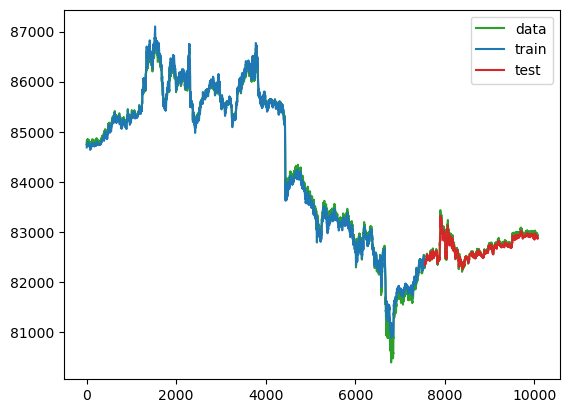

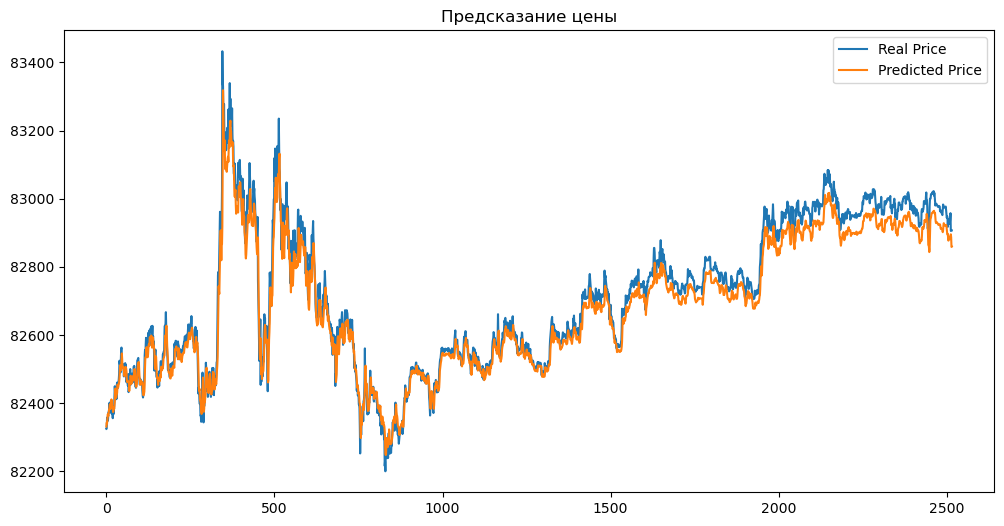

          TRAIN       TEST
rmse  87.173296  44.847696
mae   63.697274  35.273108
mape   0.000760   0.000426


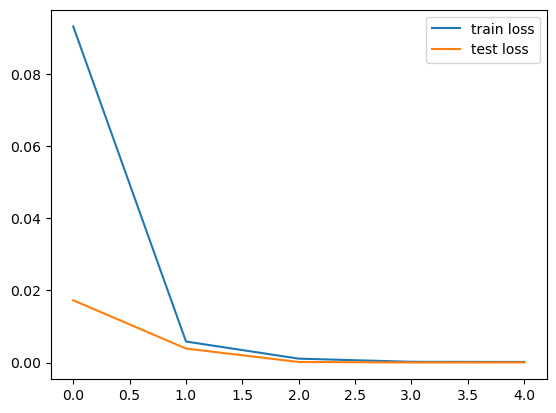


Running FuzzyLSTM ...
Среднее изменение: 22.47 $
Медианное изменение: 14.58 $
Стандартное отклонение изменений: 26.77 $
Epoch 1/5
236/236 [==============================] - 2s 3ms/step - loss: 0.0147 - val_loss: 6.2313e-04
Epoch 2/5
236/236 [==============================] - 0s 2ms/step - loss: 0.0022 - val_loss: 3.9580e-04
Epoch 3/5
236/236 [==============================] - 0s 1ms/step - loss: 8.9195e-04 - val_loss: 8.7065e-05
Epoch 4/5
236/236 [==============================] - 0s 1ms/step - loss: 3.3926e-04 - val_loss: 3.8043e-05
Epoch 5/5
236/236 [==============================] - 0s 1ms/step - loss: 1.5760e-04 - val_loss: 3.2130e-05
time = 3.72s
79/79 [==============================] - 0s 458us/step
          TRAIN       TEST
rmse  77.116329  37.358244
mae   62.086700  29.772755
mape   0.000733   0.000360


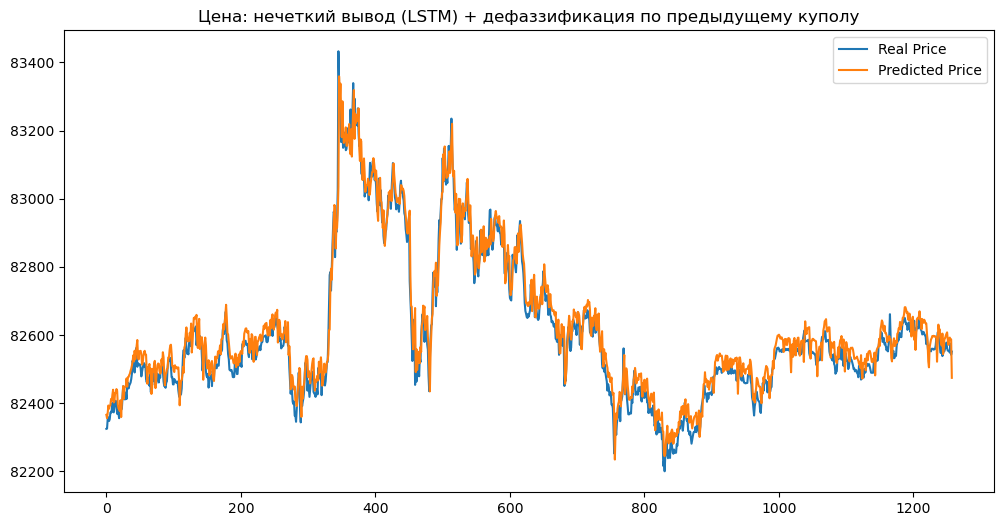

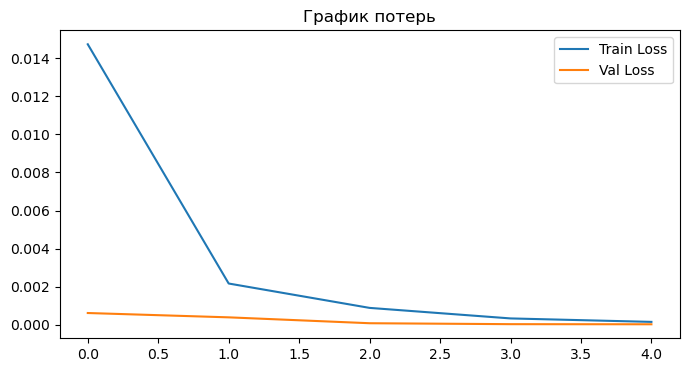


Finished. Test metrics:


,RMSE,MAE,MAPE_percent,train_seconds
model,,,,
vanilla_LSTM,44.8477,35.2731,0.0426,3.6856
FuzzyLSTM,37.3582,29.7728,0.0360,3.7151


In [32]:
if EPOCHS < 1 or BATCH_SIZE < 1 or UNITS < 1 or LOOKBACK < 1 or WINDOW < 2:
    raise ValueError('epochs / batch / units / lookback 必须为正，window 至少为 2。')
if not any(RUN_MODELS.values()):
    raise ValueError('请至少启用一个模型。')

data_preview = get_historical_close_data(COMPANIES, STEP)
train_size = int(len(data_preview) * 0.75)
if min(train_size, len(data_preview) - train_size) < LOOKBACK + 2:
    raise ValueError('数据不足以构造训练/测试窗口；请降低 lookback 或检查下载数据。')
print(f'Close range: {data_preview["Close"].min():.2f} .. {data_preview["Close"].max():.2f} USD')
print(f'Rows: {len(data_preview)} | epochs: {EPOCHS} | lookback: {LOOKBACK}')

EXPERIMENT_RESULTS.clear()
trained_models = {}
for name, enabled in RUN_MODELS.items():
    if not enabled:
        continue
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    plt.close('all')
    print(f'\nRunning {name} ...')
    args = [STEP, UNITS, COMPANIES, LOOKBACK]
    if name in ('Fuzzydata', 'FuzzyLSTM'):
        args.append(WINDOW)
    trained_models[name] = globals()[name](*args)

print('\nFinished. Test metrics:')
summary = pd.DataFrame(EXPERIMENT_RESULTS).set_index('model')
display(summary.round(4))


**如何理解结果**

- RMSE、MAE 越小，价格预测误差越低；`MAPE_percent` 为百分数。
- 五轮训练只用于检查流程和看图，不保证模糊模型比基线更好。
- 所有模型使用本次缓存的同一行情，但原始归一化与 shuffle 差异保留，因此此比较仍不是严格消融实验。
- `trained_models['FuzzyLSTM']` 可以访问训练后的模型；本单元重新运行会重新训练。
- CPU 和 GPU 可以运行相同算法，但随机性与浮点计算可能导致结果不完全一致。
